# Baseline – Parkinson's voice dataset

Week 2 · Maxence Périnel, Octave Goudon

FR – Dans ce notebook on construit des modèles très simples et on les évalue correctement. Leurs scores serviront de référence : les modèles de la semaine prochaine devront les battre, donc la méthode d'évaluation doit être fiable.

EN – In this notebook we build very simple models and evaluate them properly. Their scores are the reference that next week's models will have to beat, so the evaluation method must be reliable.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (make_scorer, recall_score, accuracy_score, balanced_accuracy_score, roc_auc_score, f1_score, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay)

## 1. Load the data

FR – On charge le fichier propre de `data_cleaning.ipynb` (755 enregistrements, 252 personnes). Les colonnes `id` (la personne), `gender` et `class` (1 = Parkinson, 0 = sain) ne sont pas des mesures de voix.

EN – We load the clean file from `data_cleaning.ipynb` (755 recordings, 252 people). The columns `id` (the person), `gender` and `class` (1 = Parkinson, 0 = healthy) are not voice measures.

In [2]:
df = pd.read_csv("../data/processed/pd_speech_clean.csv")
print(df.shape)
df[["id", "gender", "class"]].head()

(755, 720)


,id,gender,class
0,0,1,1
1,0,1,1
2,0,1,1
3,1,0,1
4,1,0,1


## 2. Learning and testing plan

FR – Les 3 enregistrements d'une personne se ressemblent, donc si certains sont dans l'entraînement et d'autres dans le test, le modèle peut reconnaître la personne au lieu de la maladie. On sépare donc les personnes : 80 % pour travailler et 20 % pour un jeu de test qu'on ne touche pas avant l'évaluation finale. On vérifie ensuite qu'aucune personne n'est dans les deux groupes.

EN – The 3 recordings of one person look alike, so if some are in the training set and others in the test set, the model can recognise the person instead of the disease. So we split the people: 80% to work with and 20% for a test set that we do not touch before the final evaluation. Then we check that nobody is in both groups.

In [ ]:
people = df.groupby("id")["class"].first()
train_ids, test_ids = train_test_split(people.index, test_size=0.2, stratify=people, random_state=42)

train = df[df["id"].isin(train_ids)]
test = df[df["id"].isin(test_ids)]

In [4]:
print("People in train:", len(train_ids), "| in test:", len(test_ids))
print("People in both sets:", len(set(train_ids) & set(test_ids)))
print("Share of Parkinson - train:", round(train["class"].mean(), 2), "| test:", round(test["class"].mean(), 2))
print("Recordings - train:", len(train), "| test:", len(test))

People in train: 201 | in test: 51
People in both sets: 0
Share of Parkinson - train: 0.75 | test: 0.75
Recordings - train: 602 | test: 153


In [ ]:
# Save the split, so that everybody uses the same people next week
split = pd.DataFrame({"id": list(train_ids) + list(test_ids), "set": ["train"] * len(train_ids) + ["test"] * len(test_ids)})
split.sort_values("id").to_csv("../data/processed/split_person_ids.csv", index=False)

# From now on we only use the training people
X = train.drop(columns=["id", "class"])
y = train["class"]
groups = train["id"]
print(X.shape)

(602, 718)


## 3. Metrics

FR – Avec 75 % de malades, un modèle qui répond toujours « Parkinson » semble bon sans rien détecter. On teste ce modèle (`DummyClassifier`) pour voir ce que donne chaque métrique. L'évaluation est une validation croisée à 5 plis groupée par personne, répétée avec 5 graines, donc chaque résultat est une moyenne ± écart-type sur 25 plis.

EN – With 75% of patients, a model that always answers "Parkinson" looks good without detecting anything. We test this model (`DummyClassifier`) to see what each metric gives. The evaluation is a 5-fold cross-validation grouped by person, repeated with 5 seeds, so each result is a mean ± standard deviation over 25 folds.

In [ ]:
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc",
    "sensitivity": "recall", # Parkinson patients found (class 1)
    "specificity": make_scorer(recall_score, pos_label=0), # healthy people found (class 0)
}

def evaluate(model, X, y, groups, by_person=True, seeds=(0, 1, 2, 3, 4)):
    results = []
    for seed in seeds: # we repeat the cross-validation 5 times
        if by_person:
            cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed) # 5 folds: a person is never split, and each fold keeps about 75% Parkinson
        else:
            cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed) # wrong on purpose, see step 4
        scores = cross_validate(model, X, y, groups=groups if by_person else None, cv=cv, scoring=scoring)
        results.append(pd.DataFrame(scores))
    return pd.concat(results) # 5 folds x 5 repetitions = 25 scores

def summarize(all_results):
    table = {}
    for model_name, r in all_results.items():
        row = {}
        for name in scoring:
            mean = r["test_" + name].mean()
            std = r["test_" + name].std()
            row[name] = f"{mean:.3f} ± {std:.3f}" # example: 0.751 ± 0.068
        table[model_name] = row
    return pd.DataFrame(table).T # one line per model

In [ ]:
dummy = DummyClassifier(strategy="most_frequent") # always answers "Parkinson"
summarize({"Dummy (always Parkinson)": evaluate(dummy, X, y, groups)})

,accuracy,balanced_accuracy,roc_auc,sensitivity,specificity
Dummy (always Parkinson),0.746 ± 0.008,0.500 ± 0.000,0.500 ± 0.000,1.000 ± 0.000,0.000 ± 0.000


FR – Le modèle « toujours Parkinson » a environ 0,75 d'accuracy (0,746) mais une spécificité de 0 : il ne retrouve aucune personne saine. L'accuracy seule est donc trompeuse. On utilisera la balanced accuracy (0,5 pour ce modèle), l'AUC, la sensibilité et la spécificité, et on garde l'accuracy seulement pour comparer avec l'article.

EN – The "always Parkinson" model has an accuracy of about 0.75 (0.746) but a specificity of 0: it finds no healthy person. Accuracy alone is therefore misleading. We will use balanced accuracy (0.5 for this model), AUC, sensitivity and specificity, and we keep accuracy only to compare with the paper.

## 4. Leakage test

FR – On vérifie que mélanger les enregistrements d'une même personne fausse vraiment les résultats. On évalue les mêmes modèles avec le bon découpage (par personne) et avec un mauvais, fait exprès (par enregistrement). Si les scores changent, c'est que le mauvais découpage laisse fuiter de l'information.

EN – We check that mixing the recordings of one person really distorts the results. We evaluate the same models with the correct split (by person) and with a wrong one, made on purpose (by recording). If the scores change, the wrong split leaks information.

In [8]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(C=1, class_weight="balanced", max_iter=5000))
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

rows = []
for name, model in [("Logistic regression", logreg), ("k-NN", knn)]:
    for by_person in [True, False]:
        r = evaluate(model, X, y, groups, by_person=by_person)
        rows.append({"model": name, "split": "by person (correct)" if by_person else "by recording (wrong)",
                     "ROC AUC": r["test_roc_auc"].mean(), "balanced accuracy": r["test_balanced_accuracy"].mean()})
leak = pd.DataFrame(rows)
leak.round(3)

,model,split,ROC AUC,balanced accuracy
0,Logistic regression,by person (correct),0.809,0.751
1,Logistic regression,by recording (wrong),0.896,0.816
2,k-NN,by person (correct),0.795,0.692
3,k-NN,by recording (wrong),0.926,0.795


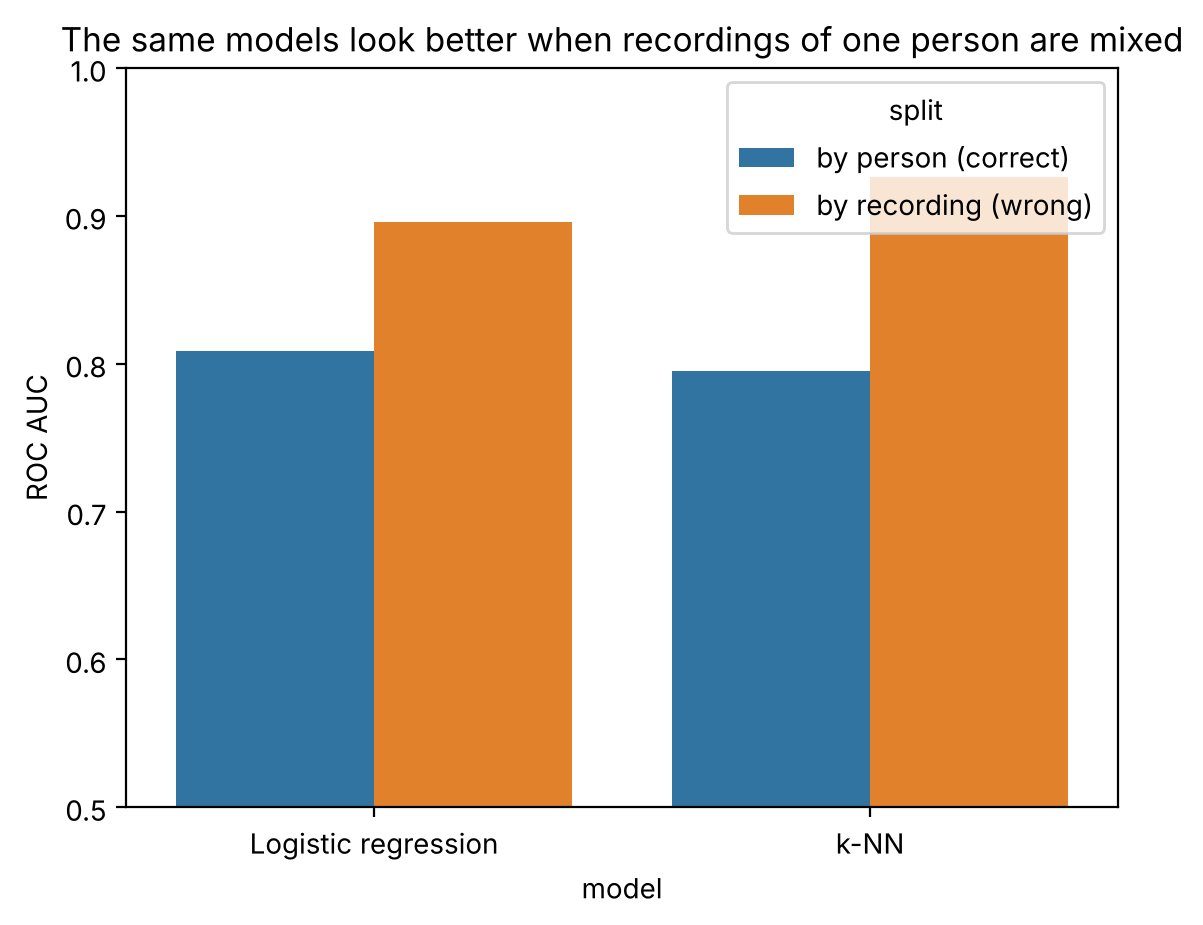

In [9]:
sns.barplot(data=leak, x="model", y="ROC AUC", hue="split")
plt.ylim(0.5, 1)
plt.title("The same models look better when recordings of one person are mixed")
plt.show()

FR – Avec le mauvais découpage, les scores montent pour les deux modèles (AUC de la régression logistique : 0,809 → 0,896 ; k-NN : 0,795 → 0,926). Ces écarts sont plus grands que l'écart-type entre plis (environ 0,06), et ils ne sont pas de la vraie performance : le modèle a déjà vu la personne à l'entraînement. Toutes les évaluations suivantes sont donc groupées par personne, et la normalisation est dans un `Pipeline` pour être calculée sur l'entraînement de chaque pli seulement.

EN – With the wrong split, the scores go up for both models (logistic regression AUC: 0.809 → 0.896; k-NN: 0.795 → 0.926). These gaps are larger than the standard deviation between folds (about 0.06), and they are not real performance: the model has already seen the person during training. All the next evaluations are therefore grouped by person, and the scaling is inside a `Pipeline` so that it is computed on the training part of each fold only.

## 5. Four simple models

FR – On compare le modèle « toujours Parkinson », une régression logistique, un arbre de décision de profondeur 4 et un k-NN (k = 5), avec des réglages simples. La régression logistique et le k-NN sont normalisés dans un `Pipeline`. Les classes sont pondérées (`class_weight="balanced"`) pour que les 25 % de personnes saines comptent autant à l'entraînement.

EN – We compare the "always Parkinson" model, a logistic regression, a decision tree of depth 4 and a k-NN (k = 5), with simple settings. The logistic regression and the k-NN are scaled inside a `Pipeline`. The classes are weighted (`class_weight="balanced"`) so that the 25% of healthy people count as much during training.

In [10]:
models = {
    "Dummy (always Parkinson)": dummy,
    "Logistic regression": logreg,
    "Decision tree": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42),
    "k-NN (k=5)": knn,
}
results = {name: evaluate(model, X, y, groups) for name, model in models.items()}
summarize(results)

,accuracy,balanced_accuracy,roc_auc,sensitivity,specificity
Dummy (always Parkinson),0.746 ± 0.008,0.500 ± 0.000,0.500 ± 0.000,1.000 ± 0.000,0.000 ± 0.000
Logistic regression,0.806 ± 0.044,0.751 ± 0.068,0.809 ± 0.061,0.862 ± 0.051,0.640 ± 0.142
Decision tree,0.742 ± 0.061,0.699 ± 0.078,0.724 ± 0.065,0.786 ± 0.072,0.611 ± 0.148
k-NN (k=5),0.804 ± 0.033,0.692 ± 0.064,0.795 ± 0.062,0.920 ± 0.041,0.463 ± 0.145


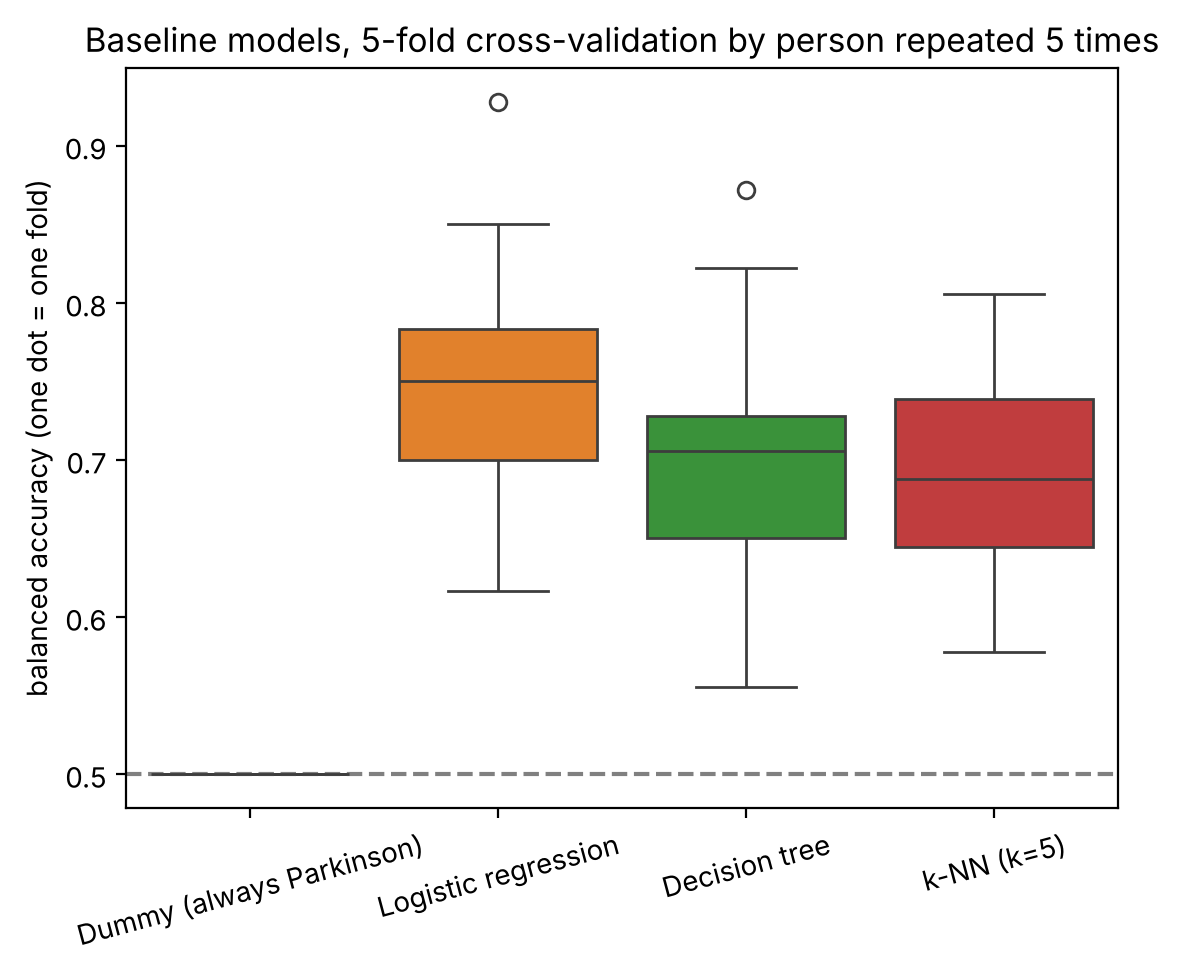

In [ ]:
data = pd.DataFrame({name: r["test_balanced_accuracy"].values for name, r in results.items()})
sns.boxplot(data=data)
plt.axhline(0.5, ls="--", color="grey")
plt.ylabel("balanced accuracy (one dot = one fold)")
plt.xticks(rotation=15)
plt.title("Baseline models, 5-fold cross-validation by person repeated 5 times")
plt.show()

FR – La régression logistique a le meilleur score moyen (balanced accuracy 0,751 ; AUC 0,809), mais l'arbre (0,699) et le k-NN (0,692) sont à moins d'un écart-type (environ 0,07) : on ne peut pas dire qu'elle est vraiment meilleure. Le k-NN retrouve presque tous les malades (sensibilité 0,92) mais seulement 46 % des personnes saines. On garde la régression logistique comme baseline parce qu'elle est simple et lisible, avec ses réglages par défaut ; les hyperparamètres seront réglés en semaine 3.

EN – The logistic regression has the best average score (balanced accuracy 0.751; AUC 0.809), but the tree (0.699) and the k-NN (0.692) are within one standard deviation (about 0.07), so we cannot say it is really better. The k-NN finds almost all patients (sensitivity 0.92) but only 46% of the healthy people. We keep the logistic regression as our baseline because it is simple and easy to read, with its default settings; the hyperparameters will be tuned in week 3.

## 6. Calibration of the probabilities

FR – Un modèle médical doit donner des probabilités fiables : quand il dit 70 %, environ 70 % de ces personnes doivent être malades. On récupère les probabilités prédites hors entraînement (`cross_val_predict`), on les range en 10 groupes de même taille et on compare la probabilité prédite à la vraie part de malades.

EN – A medical model must give reliable probabilities: when it says 70%, about 70% of these people should be ill. We collect the out-of-fold predicted probabilities (`cross_val_predict`), sort them into 10 groups of the same size and compare the predicted probability with the real share of patients.

In [12]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
# cross_val_predict: for each fold, train on the other folds and predict the left-out fold,
# so each recording is predicted by a model that has never seen this person
proba = cross_val_predict(logreg, X, y, groups=groups, cv=cv, method="predict_proba")[:, 1]

# calibration_curve: 10 groups of recordings with the same size (strategy="quantile"), sorted by predicted probability;
# for each group: mean predicted probability and real share of Parkinson
observed, predicted = calibration_curve(y, proba, n_bins=10, strategy="quantile")
table = pd.DataFrame({"mean predicted probability": predicted, "observed share of Parkinson": observed})
table.round(2)

,mean predicted probability,observed share of Parkinson
0,0.00,0.23
1,0.04,0.43
2,0.33,0.70
3,0.77,0.73
4,0.97,0.87
5,0.99,0.90
6,1.00,0.90
7,1.00,0.95
8,1.00,0.85
9,1.00,0.90


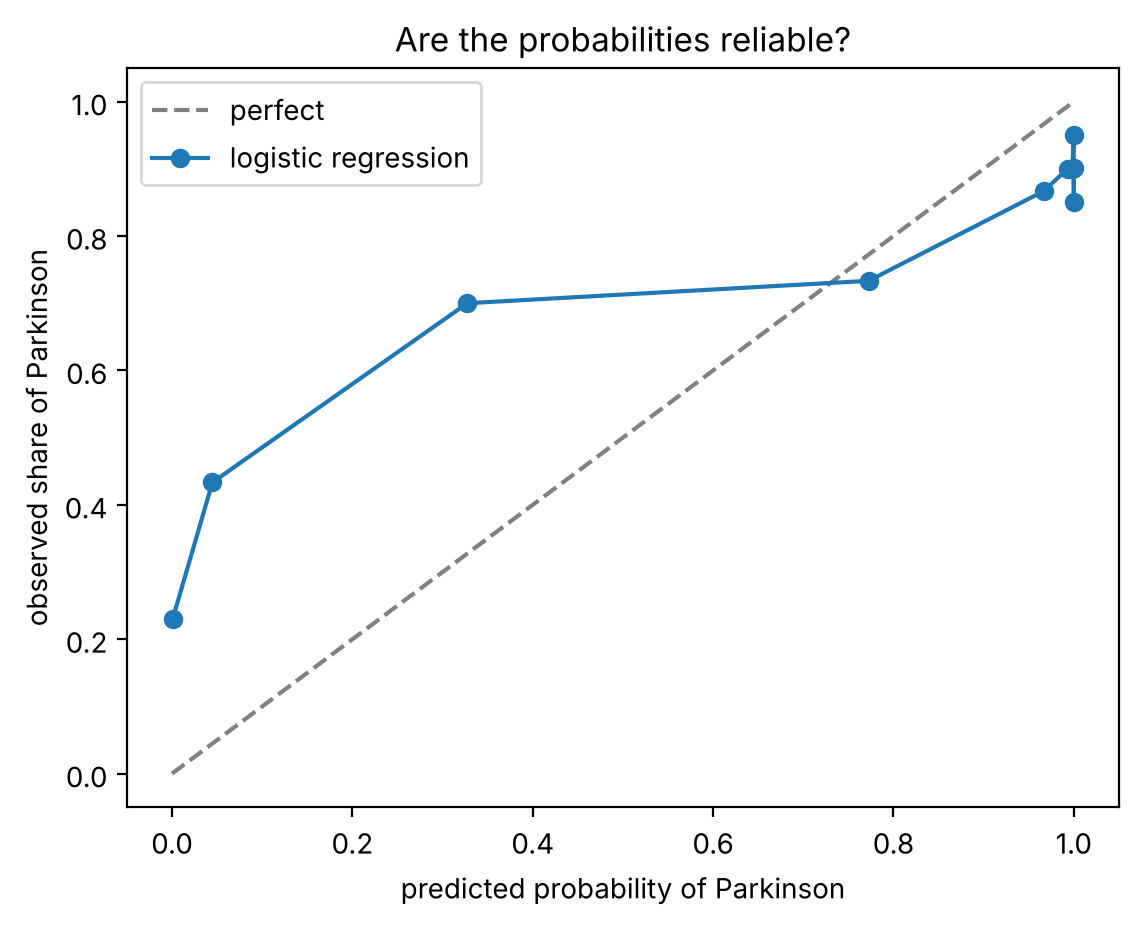

In [13]:
plt.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
plt.plot(predicted, observed, marker="o", label="logistic regression")
plt.xlabel("predicted probability of Parkinson")
plt.ylabel("observed share of Parkinson")
plt.title("Are the probabilities reliable?")
plt.legend()
plt.show()

FR – Les probabilités sont trop sûres d'elles. Quand le modèle prédit environ 0, 23 % de ces enregistrements sont en fait des malades, et à 0,04 c'est 43 %. En haut, une probabilité de 1,00 correspond à 85–95 % de malades. On ne doit donc pas lire ces probabilités comme de vrais risques ; on essaiera une calibration (par exemple `CalibratedClassifierCV`) en semaine 3.

EN – The probabilities are over-confident. When the model predicts about 0, 23% of these recordings are actually patients, and at 0.04 it is 43%. At the top, a probability of 1.00 matches 85–95% of patients. So these probabilities must not be read as real risks; we will try a calibration (for example `CalibratedClassifierCV`) in week 3.

## 7. Per recording or per person

FR – Ce qui nous intéresse, c'est si une personne est malade, pas un enregistrement. Comme chaque personne a 3 enregistrements, on fait la moyenne de ses probabilités pour avoir une seule prédiction, et on la compare à la prédiction par enregistrement (mêmes probabilités hors entraînement).

EN – What we care about is whether a person is ill, not one recording. Since each person has 3 recordings, we average their probabilities to get a single prediction, and we compare it with the per-recording prediction (same out-of-fold probabilities).

In [14]:
def scores(y_true, proba):
    pred = (proba >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y_true, pred), "balanced accuracy": balanced_accuracy_score(y_true, pred),
            "ROC AUC": roc_auc_score(y_true, proba), "sensitivity": recall_score(y_true, pred, pos_label=1),
            "specificity": recall_score(y_true, pred, pos_label=0), "F1": f1_score(y_true, pred),
            "MCC": matthews_corrcoef(y_true, pred)}

# One probability per person = average of the probabilities of its recordings
per_person = pd.DataFrame({"id": groups.values, "class": y.values, "proba": proba}).groupby("id").mean()

table = pd.DataFrame({"per recording": scores(y.values, proba),
                      "per person": scores(per_person["class"].values, per_person["proba"].values)}).T
table.round(3)

,accuracy,balanced accuracy,ROC AUC,sensitivity,specificity,F1,MCC
per recording,0.782,0.738,0.789,0.829,0.647,0.850,0.455
per person,0.806,0.754,0.835,0.860,0.647,0.869,0.498


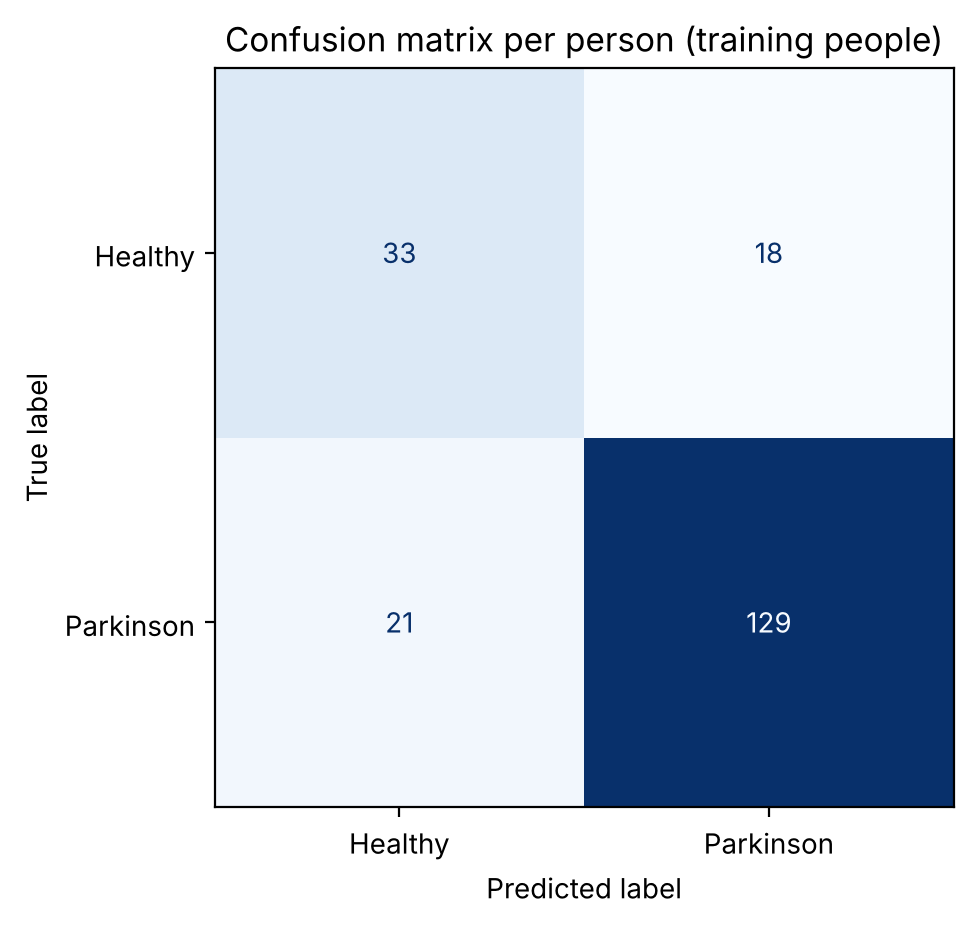

Patients missed: 21 / 150 | Healthy people wrongly flagged: 18 / 51


In [15]:
pred_person = (per_person["proba"] >= 0.5).astype(int)
ConfusionMatrixDisplay(confusion_matrix(per_person["class"], pred_person), display_labels=["Healthy", "Parkinson"]).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix per person (training people)")
plt.show()

tn, fp, fn, tp = confusion_matrix(per_person["class"], pred_person).ravel()
print(f"Patients missed: {fn} / {fn + tp} | Healthy people wrongly flagged: {fp} / {fp + tn}")

FR – Par personne, les scores sont un peu plus hauts (balanced accuracy 0,738 → 0,754 ; AUC 0,789 → 0,835 ; MCC 0,455 → 0,498), ce qui est logique car la moyenne réduit le bruit d'un enregistrement. Mais ces chiffres viennent d'une seule série de prédictions, sans écart-type, donc il faut rester prudent. La matrice de confusion montre 21 malades manqués sur 150 et 18 personnes saines signalées à tort sur 51. On calculera la métrique finale par personne, comme dans l'article.

EN – Per person, the scores are a bit higher (balanced accuracy 0.738 → 0.754; AUC 0.789 → 0.835; MCC 0.455 → 0.498), which makes sense because averaging reduces the noise of one recording. But these numbers come from a single set of predictions, with no standard deviation, so we stay careful. The confusion matrix shows 21 patients missed out of 150 and 18 healthy people wrongly flagged out of 51. We will compute the final metric per person, as in the paper.

## 8. Feature selection

FR – Beaucoup de features sont des quasi-copies (voir `data_cleaning.ipynb`), et on veut savoir si en enlever fait baisser les scores. On fait cette étape ici, et pas dans le notebook de nettoyage, parce que le filtre doit être calculé sur les personnes d'entraînement seulement, pour que le jeu de test n'influence pas le choix. On teste les seuils de corrélation 0,99, 0,95 et 0,90 (plus le seuil est bas, plus on enlève de features).

EN – Many features are near-copies (see `data_cleaning.ipynb`), and we want to know if removing them lowers the scores. We do this step here, and not in the cleaning notebook, because the filter must be computed on the training people only, so that the test set does not influence the choice. We test the correlation thresholds 0.99, 0.95 and 0.90 (the lower the threshold, the more features are removed).

In [ ]:
def columns_to_remove(data, threshold):
    corr = data.corr().abs().values # table of the correlations between all pairs of columns
    names = list(data.columns)
    to_remove = []
    for j in range(len(names)):             
        for i in range(j):                   
            if corr[i, j] > threshold:     
                to_remove.append(names[j]) 
                break
    return to_remove

voice = X.drop(columns="gender")
removed_train = columns_to_remove(voice, 0.99)   

reduced_file = pd.read_csv("../data/processed/pd_speech_reduced.csv")
removed_all = set(df.columns) - set(reduced_file.columns)    
print("Removed with the training people only:", len(removed_train))
print("Removed with all the people:", len(removed_all))
print("In both lists:", len(set(removed_train) & removed_all))

Removed with the training people only: 99
Removed with all the people: 97
In both lists: 94


In [ ]:
rows = []
for threshold in [1.0, 0.99, 0.95, 0.90]:                       
    removed = columns_to_remove(voice, threshold) if threshold < 1 else []
    X_small = X.drop(columns=removed)
    r = evaluate(logreg, X_small, y, groups)
    rows.append({"threshold": threshold, "voice features": X_small.shape[1] - 1,
                 "balanced accuracy": r["test_balanced_accuracy"].mean(), "std": r["test_balanced_accuracy"].std(),
                 "ROC AUC": r["test_roc_auc"].mean()})
reduction = pd.DataFrame(rows)
reduction.round(3)

,threshold,voice features,balanced accuracy,std,ROC AUC
0,1.00,717,0.751,0.068,0.809
1,0.99,618,0.754,0.071,0.808
2,0.95,469,0.744,0.074,0.807
3,0.90,354,0.738,0.066,0.804


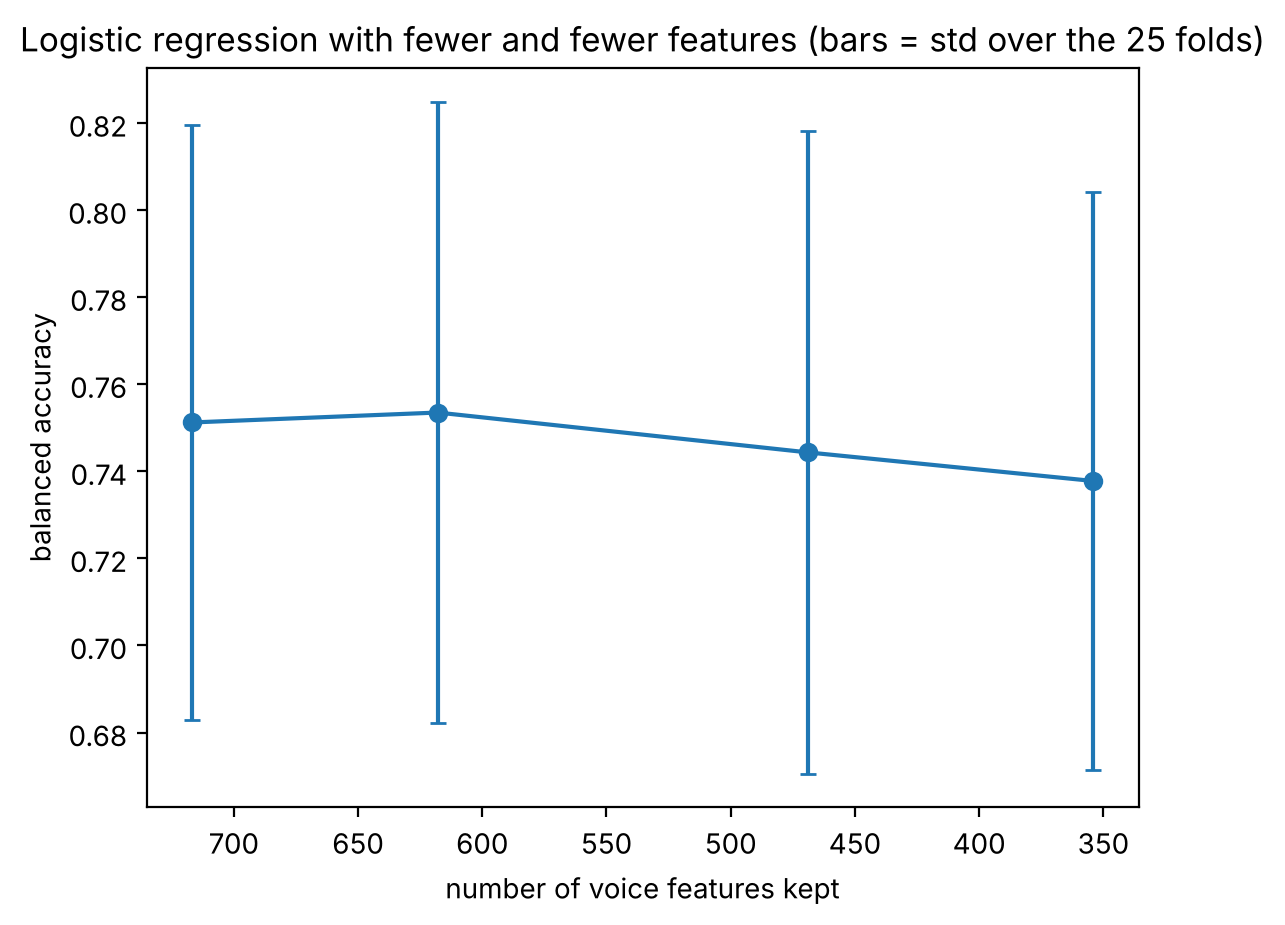

In [18]:
plt.errorbar(reduction["voice features"], reduction["balanced accuracy"], yerr=reduction["std"], marker="o", capsize=3)
plt.gca().invert_xaxis()
plt.xlabel("number of voice features kept")
plt.ylabel("balanced accuracy")
plt.title("Logistic regression with fewer and fewer features (bars = std over the 25 folds)")
plt.show()

FR – Avec les personnes d'entraînement, le filtre supprime 99 colonnes, contre 97 avec toutes les personnes (94 en commun). Avec 717, 618, 469 puis 354 features de voix, la balanced accuracy est de 0,751, 0,754, 0,744 et 0,738 : les écarts sont bien plus petits que l'écart-type (environ 0,07), donc on ne voit pas de différence nette. On garde le seuil 0,99 par défaut parce que les scores baissent un peu quand on enlève davantage. Limite : le filtre n'utilise pas les classes, mais il est calculé sur tout l'entraînement et pas dans chaque pli ; on pense que l'effet est petit sans l'avoir mesuré.

EN – With the training people, the filter removes 99 columns, against 97 with all the people (94 in common). With 717, 618, 469 and then 354 voice features, the balanced accuracy is 0.751, 0.754, 0.744 and 0.738: the gaps are much smaller than the standard deviation (about 0.07), so we see no clear difference. We keep the 0.99 threshold by default because the scores go down a little when we remove more. Limitation: the filter does not use the classes, but it is computed on the whole training set and not inside each fold; we think the effect is small but we did not measure it.

## 9. Gender

FR – On regarde si le genre est réparti de la même façon dans les deux classes, et si le modèle s'en sert comme raccourci. Pour cela on compare les scores avec et sans cette colonne.

EN – We look at whether gender is spread in the same way in the two classes, and whether the model uses it as a shortcut. To do this we compare the scores with and without this column.

In [19]:
people_train = train.groupby("id")[["class", "gender"]].first()
print(pd.crosstab(people_train["gender"], people_train["class"].map({0: "Healthy", 1: "Parkinson"})))
print()
print(pd.crosstab(people_train["gender"], people_train["class"].map({0: "Healthy", 1: "Parkinson"}), normalize="index").round(2))

class   Healthy  Parkinson
gender                    
0            31         60
1            20         90

class   Healthy  Parkinson
gender                    
0          0.34       0.66
1          0.18       0.82


In [20]:
without_gender = evaluate(logreg, X.drop(columns="gender"), y, groups)
summarize({"with gender": results["Logistic regression"], "without gender": without_gender})

,accuracy,balanced_accuracy,roc_auc,sensitivity,specificity
with gender,0.806 ± 0.044,0.751 ± 0.068,0.809 ± 0.061,0.862 ± 0.051,0.640 ± 0.142
without gender,0.806 ± 0.040,0.753 ± 0.063,0.807 ± 0.061,0.861 ± 0.050,0.645 ± 0.137


FR – Le genre n'est pas équilibré : 34 % des personnes avec gender=0 sont saines, contre 18 % avec gender=1. Pourtant, enlever la colonne ne change pas les scores (balanced accuracy 0,751 avec, 0,753 sans), donc rien ne montre que le modèle s'en sert comme raccourci. On garde la colonne et on revérifiera avec le modèle final.

EN – Gender is not balanced: 34% of the people with gender=0 are healthy, against 18% with gender=1. Still, removing the column does not change the scores (balanced accuracy 0.751 with, 0.753 without), so nothing shows that the model uses it as a shortcut. We keep the column and will check again with the final model.

## 10. Comparison with the paper

FR – On place nos scores par personne à côté de ceux de Sakar et al. (2019), les auteurs du jeu de données, pour savoir où on se situe.

EN – We put our per-person scores next to those of Sakar et al. (2019), the authors of the dataset, to see where we stand.

In [21]:
ours = scores(per_person["class"].values, per_person["proba"].values)
benchmark = pd.DataFrame([
    {"model": "Our baseline: logistic regression, all features", "validation": "5-fold by person (201 people)",
     "accuracy": ours["accuracy"], "F1": ours["F1"], "MCC": ours["MCC"]},
    {"model": "Sakar et al.: SVM (RBF), MFCC only", "validation": "leave-one-subject-out (252 people)",
     "accuracy": 0.84, "F1": 0.83, "MCC": 0.54},
    {"model": "Sakar et al.: MLP, TQWT only", "validation": "leave-one-subject-out (252 people)",
     "accuracy": 0.85, "F1": 0.84, "MCC": 0.57},
    {"model": "Sakar et al.: SVM (RBF), top-50 features chosen by mRMR", "validation": "leave-one-subject-out (252 people)",
     "accuracy": 0.86, "F1": 0.84, "MCC": 0.59},
])
benchmark.round(2)

,model,validation,accuracy,F1,MCC
0,"Our baseline: logistic regression, all features",5-fold by person (201 people),0.81,0.87,0.50
1,"Sakar et al.: SVM (RBF), MFCC only",leave-one-subject-out (252 people),0.84,0.83,0.54
2,"Sakar et al.: MLP, TQWT only",leave-one-subject-out (252 people),0.85,0.84,0.57
3,"Sakar et al.: SVM (RBF), top-50 features chose...",leave-one-subject-out (252 people),0.86,0.84,0.59


FR – Notre baseline (accuracy 0,81 ; F1 0,87 ; MCC 0,50) est en dessous du meilleur résultat de l'article sur l'accuracy et le MCC (0,86 et 0,59), mais au-dessus sur le F1 (0,87 contre 0,84). La comparaison n'est pas exacte : nous avons une validation à 5 plis par personne sur 201 personnes, sans sélection de features, alors qu'ils font du leave-one-subject-out sur 252 personnes avec une sélection de 50 features (mRMR). On ne peut donc pas conclure qui est meilleur.

EN – Our baseline (accuracy 0.81; F1 0.87; MCC 0.50) is below the best result of the paper on accuracy and MCC (0.86 and 0.59), but above on F1 (0.87 against 0.84). The comparison is not exact: we use a 5-fold validation by person on 201 people, without feature selection, whereas they use leave-one-subject-out on 252 people with a selection of 50 features (mRMR). So we cannot conclude who is better.

## Conclusion

FR – On sépare par personne et on garde 20 % des personnes pour un test final. La régression logistique a le meilleur score moyen (balanced accuracy 0,751 ; AUC 0,809), mais sans écart net avec l'arbre et le k-NN, et on la garde comme baseline. Les probabilités sont trop sûres d'elles, et on peut enlever les quasi-copies sans voir de baisse nette des scores. La semaine 3 portera sur l'AutoML, des modèles plus riches (random forest, SVM RBF, gradient boosting), le réglage des hyperparamètres, la calibration et une évaluation plus proche de celle de l'article.

EN – We split by person and keep 20% of the people for a final test. The logistic regression has the best average score (balanced accuracy 0.751; AUC 0.809), but with no clear gap to the tree and the k-NN, and we keep it as our baseline. The probabilities are over-confident, and we can remove near-copies without seeing a clear drop in the scores. Week 3 will cover AutoML, richer models (random forest, RBF SVM, gradient boosting), hyperparameter tuning, calibration and an evaluation closer to the paper's.